# Neuron Model and Network Architecture

1. Single-Input Neuron
2. Transfer Functions
3. Multiple-Input Neuron
4. Layer of Neurons
5. Abbreviated Notation
6. Multilayer Network
7. Abreviated Notation
8. Delays and Integrators
9. Recurrent Network

## 1. Single-Input Neuron


![](images/single_input_neuron.png)

 $$\displaystyle \LARGE \text{p = Scalar Input      }$$
 $$\displaystyle \LARGE \text{w = Scalar Weight}$$
 $$\displaystyle \LARGE \text{b = Bias}$$
 $$\displaystyle \LARGE \text{n = Net Input}$$
 $$\displaystyle \LARGE \text{f = Transfer function}$$
 $$\displaystyle \LARGE \text{a = Scalar output     }$$


![](images/single_input_neuron_statement.png)

In [1]:
#p = Scalar Input 
#w = Scalar Weight   
#b = Bias             
#n = Net Input         
#f = Transfer function 
#a = Scalar output

In [2]:
p = 2
w = 3
b = -1.5

def f(p=0,w=1,b=1):
    return p*w + b
    

a = f(p,w,b)
a



4.5

## 2. Transfer Functions


 1. Hard Limit
 2. Symmetrical Hard Limit
 3. Linear
 4. Saturating Linear
 5. Symmetric Saturating Linear
 6. Log-Sigmoid
 7. Hyperbolic Tangent Sigmoid
 8. Positive Linear
 9. Competitive

In [3]:
#!pip install matplotlib numpy

In [4]:
#!pip install jupyter-matlab-proxy matlab_kernel

### 1. Hard Limit


$$
\LARGE \operatorname{hardlim}(x)=
\begin{cases}
0 & x<0\\
1 & x\geq 0
\end{cases}
$$



In [5]:
def hardlim(n):
   return (n>=0).astype(int)

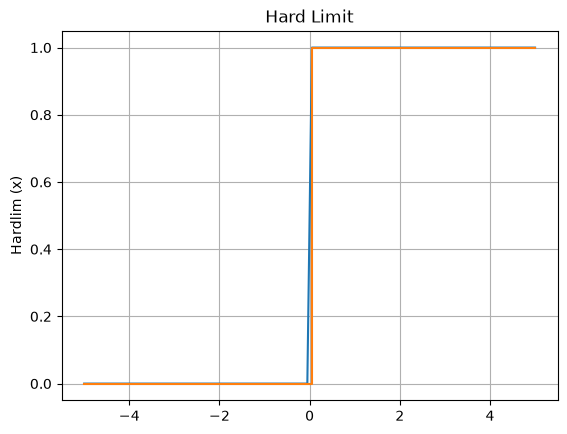

In [6]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = hardlim(x)
plt.plot(x,y)
plt.step(x, y, where="post")
plt.title("Hard Limit")
plt.ylabel("Hardlim (x)")
plt.grid(True)
plt.show()


 ### 2. Symmetrical Hard Limit

 
$$
\LARGE \operatorname{hardlims}(x)=
\begin{cases}
-1 & x<0\\
+1 & x\geq 0
\end{cases}
$$


 

In [7]:
def hardlims(x):
   return (x>=0)*1 + (x<0)*-1

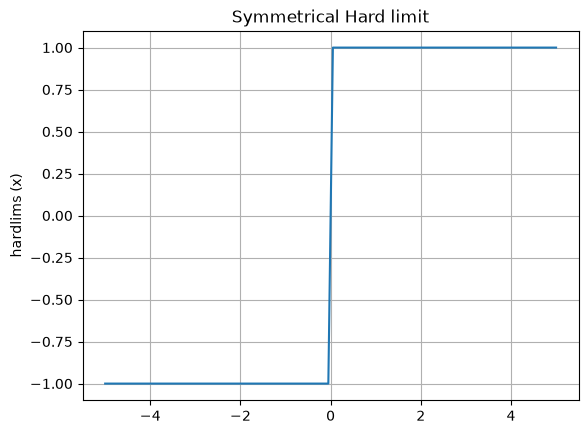

In [8]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = hardlims(x)

#%timeit hardlims(x)

plt.plot(x, y)
plt.title("Symmetrical Hard limit")
plt.ylabel("hardlims (x)")
plt.grid(True)
plt.show()


### 3. Linear

$$
\LARGE  a = n
$$



In [9]:
def purelin(x):
    return x


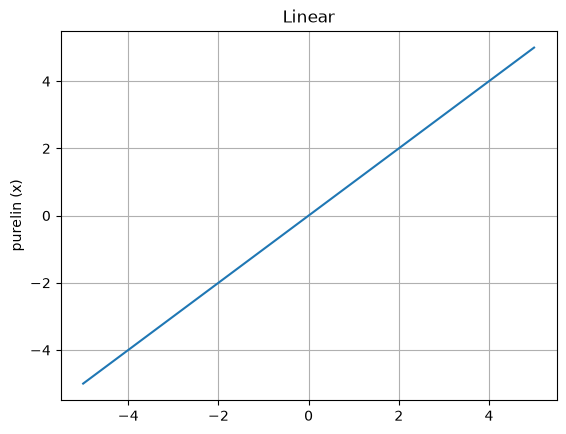

In [10]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = purelin(x)

#%timeit purelin(x)

plt.plot(x, y)
plt.title("Linear")
plt.ylabel("purelin (x)")
plt.grid(True)
plt.show()


### 4. Saturating Linear


$$
\LARGE  \operatorname{satlin}(x)=
\begin{cases}
0 & x<0\\
x & 0\leq x \leq 1 \\
1 & x > 1
\end{cases}
$$



In [11]:
def satlin(x):
    return ((x >= 0) & (x <= 1)) * x + (x < 0) * 0 + (x > 1) * 1


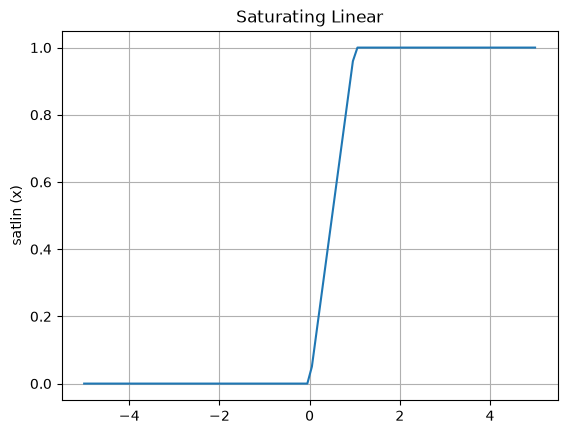

In [12]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = satlin(x)

#%timeit satlin(x)

plt.plot(x, y)
plt.title("Saturating Linear")
plt.ylabel("satlin (x)")
plt.grid(True)
plt.show()


### 5. Symmetric Saturating Linear

$$
\LARGE \operatorname{satlins}(x)=
\begin{cases}
-1 & x< -1 \\
x & -1 \leq x \leq 1 \\
1 & x > 1
\end{cases}
$$


In [13]:
def satlins(x):
    return ((x >= -1) & (x <= 1)) * x + (x < -1) * -1 + (x > 1) * 1


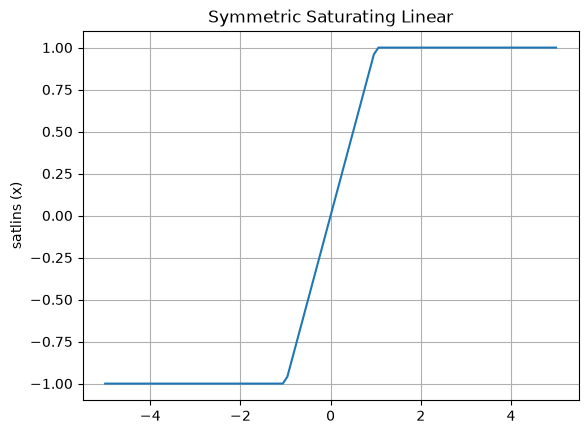

In [14]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = satlins(x)

#%timeit satlins(x)

plt.plot(x, y)
plt.title("Symmetric Saturating Linear")
plt.ylabel("satlins (x)")
plt.grid(True)
plt.show()


### 6. Log-Sigmoid

$$
\LARGE \operatorname{logsig}(x)=
\frac{1}{1+e^{-n}}
$$


In [15]:
import math

def logsig(x):
    #return 1 / (1 + (math.e**(-x)))
    return 1 / (1 + np.exp(-x))
    

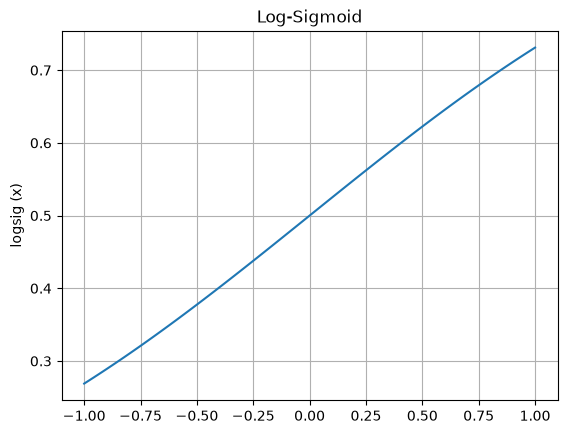

In [16]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-1,1,100)
y = logsig(x)

#%timeit logsig(x)

plt.plot(x, y)
plt.title("Log-Sigmoid")
plt.ylabel("logsig (x)")
plt.grid(True)
plt.show()


### 7. Hyperbolic Tangent Sigmoid

$$
\LARGE \operatorname{tansig}(x)=
\frac{e^n - e^{-n}}{e^n + e^{-n}}
$$


In [17]:
import math

def tansig(x):
    #return ((math.e**x) - (math.e**(-x)))/((math.e**x) + (math.e**(-x)))
    #return (np.exp(x) - np.exp(-x)) / (np.exp(x) + np.exp(-x))
    return np.tanh(x)

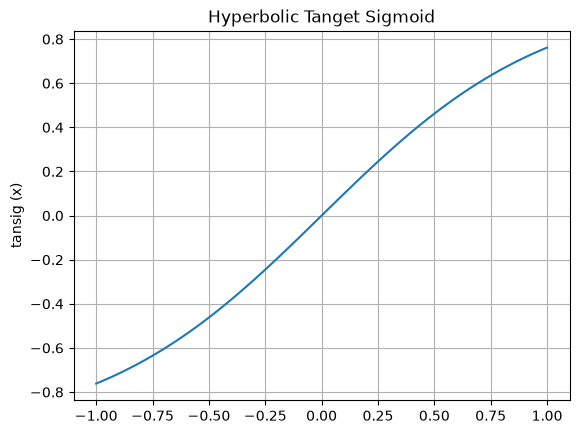

In [18]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-1,1,100)
y = tansig(x)

#%timeit poslin(x)

plt.plot(x, y)
plt.title("Hyperbolic Tanget Sigmoid")
plt.ylabel("tansig (x)")
plt.grid(True)
plt.show()


### 8. Positive Linear

$$
\LARGE  \operatorname{poslin}(x)=
\begin{cases}
0 & x<0 \\
x & 0 \leq x
\end{cases}
$$



In [19]:
def poslin(x):
    return (x >= 0) * x

1.76 μs ± 19.5 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


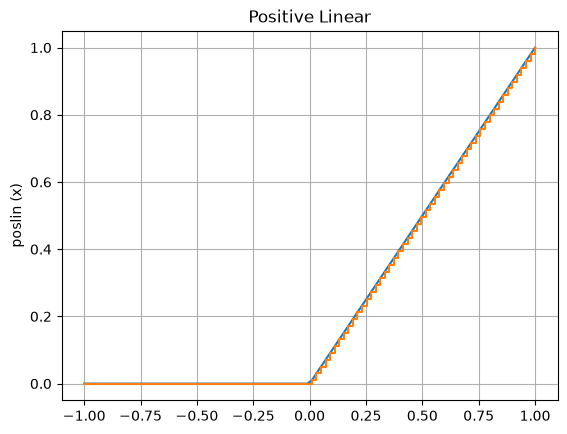

In [20]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-1,1,100)
y = poslin(x)
%timeit poslin(x)

plt.plot(x, y)
plt.step(x, y, where="post")
plt.title("Positive Linear")
plt.ylabel("poslin (x)")
plt.grid(True)
plt.show()


### 9. Competitive
$$
\LARGE \operatorname{compet}(x)=
\begin{cases}
1 & \text{neuron with max n}\\
0 & \text{all other neurons}
\end{cases}
$$


In [21]:
def compet(n):
    y = np.zeros_like(n, dtype=int)
    y[np.argmax(x)] = 1
    return y

2.8 μs ± 274 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


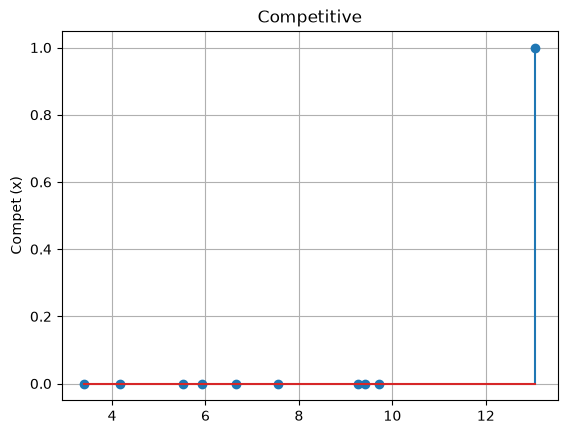

In [22]:
import matplotlib.pyplot as plt
import numpy as np
np.random.seed(123)

#x = np.random.rand(100)
x = np.random.uniform(low=0.5, high=13.3, size=(10,))

y = compet(x)
#plt.hist2d(x,y)
%timeit compet(x)

plt.stem(x, y)
#plt.bar(x, y)
#plt.scatter(x,y)
#plt.step(x, y, where="post")
plt.title("Competitive")
plt.ylabel("Compet (x)")
plt.grid(True)
plt.show()


## 3. Multiple-Input Neuron

![](images/multiple_input_neuron.png)

### Weight Matrix 

A neuron has more than one input. A neuron with $\textbf{R}$ inputs is
shown in Figure 2.5. The individual inputs $p_1, p_2, \cdots, p_R$ are each weighted by
corresponding elements $w_{1,1},w_{1,2},\cdots, w_{1,R}$ of the weight matrix $\textbf{W}$.

he neuron has a bias $b$, which is summed with the weighted inputs to
form the net input $n$:

$$\displaystyle \LARGE n = w_{1,1}p_1 + w_{1,2}p_2 + \cdots + w_{1,R}p_R + b$$

This expression can be written in matrix form:

$$ \LARGE n = \textbf{Wp} +b $$

where the matrix $\textbf{W}$ for the single neuron case has only one row.

$$\LARGE a = f(\textbf{Wp}+b)$$

Fortunately, $\LARGE \textbf{neural networks can often be described with matrices}$. This
kind of matrix expression will be used throughout the book. Don’t be con-
cerned if you are rusty with matrix and vector operations. $\LARGE \textbf{We will review
these topics in Chapters 5 and 6}$, and we will provide many examples and
solved problems that will spell out the procedures.


In [23]:
import numpy as np

np.random.seed(181)

neuron_length = 4


w = np.random.rand(neuron_length) # Weight
print(f"Weight (W) = {w}")
print(f"Weight (W) - Dimentsion = {w.shape}")

p = np.linspace(-10,10,neuron_length)
print(f"Input (p) = {p}")
print(f"Input (p) - Dimentsion = {w.shape}")

Wp = np.dot(w,p)
print(f"Wp = {Wp}")

b = 1 

n = Wp + b

print(f"a = f(Wp + 1) = {n}")

a = tansig(np.array(n))

print(f"a = tansig(Wp + 1) = {a}")


Weight (W) = [0.52402311 0.11408956 0.57056722 0.40583553]
Weight (W) - Dimentsion = (4,)
Input (p) = [-10.          -3.33333333   3.33333333  10.        ]
Input (p) - Dimentsion = (4,)
Wp = 0.3397164132323738
a = f(Wp + 1) = 1.3397164132323738
a = tansig(Wp + 1) = 0.8716041163549962


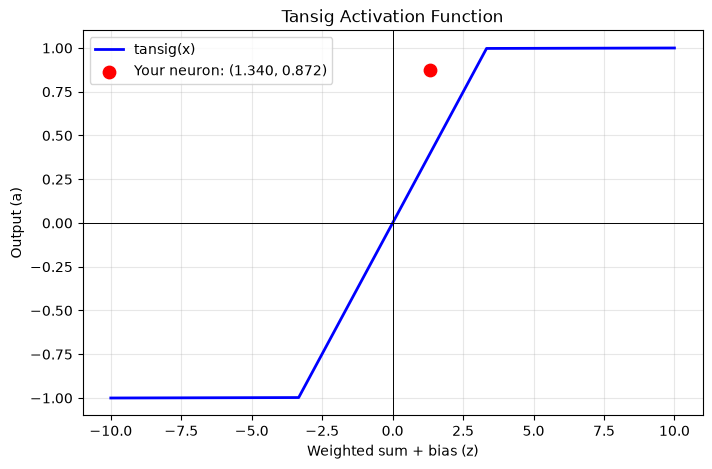

In [24]:

import numpy as np
import matplotlib.pyplot as plt



y = tansig(p)

plt.figure(figsize=(8, 5))
#plt.bar(p,y)
plt.plot(p, y, color="blue", linewidth=2, label="tansig(x)")
plt.axhline(0, color="black", linewidth=0.7)
plt.axvline(0, color="black", linewidth=0.7)
plt.scatter([n], [a], color="red", s=80,
            label=f"Your neuron: ({n:.3f}, {a:.3f})")
plt.xlabel("Weighted sum + bias (z)")
plt.ylabel("Output (a)")
plt.title("Tansig Activation Function")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [25]:
import sys
import struct

print("Python Version:", sys.version)
print("Architecture Bit Depth:", struct.calcsize('P') * 8)


Python Version: 3.12.15 (main, Oct 13 2026, 16:52:04) [GCC 15.3.0]
Architecture Bit Depth: 64


In [26]:
#!pip install tensorflow visualkeras 

In [27]:
#!pip install --index-url https://download.pytorch.org/whl/cpu

In [28]:
#!pip install graphviz

In [29]:
from visualizer.v0 import visualize

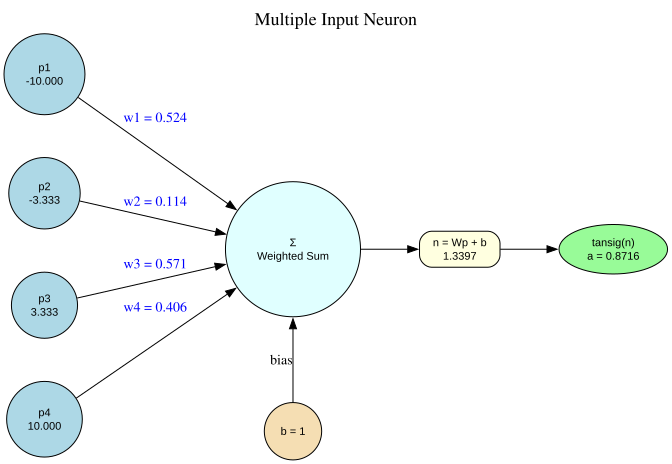

In [30]:
visualize(p,w,b,n,a)

### Weight Indices

We have adopted a particular convention in **assigning the indices of the elements of the weight matrix**. The $\textbf{first index}$ indicates $\textbf{the particular neuron destination for that weight}$.
The **second index** indicates **the source of the signal fed to the neuron**. Thus, the indices in $w_{1,2}$ say that this weight represents **the connection to the first (and only) neuron from the second
source**. Of course, **this convention** is **more useful if there is more than one
neuron**, as will be the case later in this chapter.

### Abbreviated Notation

We would **like to draw networks with several neurons, each having several
inputs**. Further, we would like to have more than one layer of neurons. **You
can imagine how complex such a network might appear if all the lines were
drawn**. It would **take a lot of ink**, could **hardly be read**, and **the mass of detail might obscure the main features**. **Thus**, we will **use an abbreviated notation**. A multiple-input neuron using this notation is shown in **Figure 2.6**.

![](images/multiple_input_neuron_abbr.png)

As shown in Figure 2.6, $\colorbox{yellow}{$\text{ the input vector  \textbf{P} is represented by the solid vertical bar at the left}$}$. The dimensions of $\textbf{P}$ are displayed below the variable as $\mathbf{R \times 1}$, indicating that the input is a single vector of $\textbf{R}$elements. These
inputs go to the weight matrix $\textbf{W}$, which has $\textbf{R}$ columns but only one row
in this single neuron case. A constant 1 enters the neuron as an input and
is multiplied by a scalar bias $\textbf{b}$. The net input to the transfer function $\textbf{f}$ is $\textbf{n}$
, which is the sum of the bias $\textbf{b}$ and the product $\textbf{Wp}$. The neuron’s output $\textbf{a}$
is a scalar in this case. If we had more than one neuron, the network output would be a vector.

The dimensions of the variables in these abbreviated notation figures will
always be included, so that you can tell immediately if we are talking about
a scalar, a vector or a matrix. You will not have to guess the kind of variable
or its dimensions.

**Note**: that the number of inputs to a network is set by the external specifications of the problem. If, for instance, $\LARGE \textbf{you want to design a neural network
that is to predict}$ kite-flying conditions and the inputs are air temperature,
wind velocity and humidity, then there would be three inputs to the network.

In [31]:
import numpy as np

np.random.seed(181)

neuron_length = 4


w = np.random.rand(neuron_length) # Weight
w = np.expand_dims(w, axis=1)

print(f"Weight (W) = {w}")
print(f"Weight (W) - Dimentsion = {w.shape}")

p = np.linspace(-10,10,neuron_length)
p = np.expand_dims(p, axis=1)

print(f"Input (p) = {p}")
print(f"Input (p) - Dimentsion = {w.shape}")

Wp = w.T @ p
print(f"Wp = {Wp}")

b = 1 

n = Wp + b

print(f"a = f(Wp + 1) = {n}")

a = tansig(np.array(n))

print(f"a = tansig(Wp + 1) = {a}")


Weight (W) = [[0.52402311]
 [0.11408956]
 [0.57056722]
 [0.40583553]]
Weight (W) - Dimentsion = (4, 1)
Input (p) = [[-10.        ]
 [ -3.33333333]
 [  3.33333333]
 [ 10.        ]]
Input (p) - Dimentsion = (4, 1)
Wp = [[0.33971641]]
a = f(Wp + 1) = [[1.33971641]]
a = tansig(Wp + 1) = [[0.87160412]]


In [32]:
from visualizer.v1 import visualize

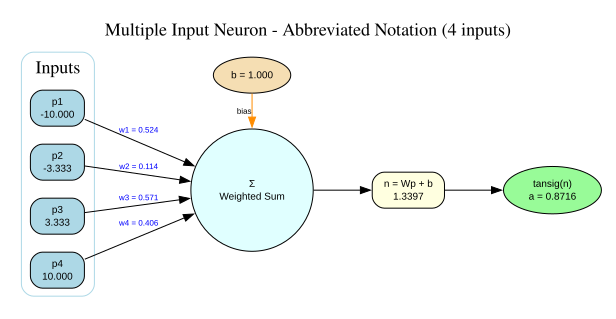

In [33]:
visualize(p,w,b,n,a)

# Network Architectures

Commonly $\LARGE \textbf{one neuron, even with many inputs, may not be sufficient}$. We
might $\LARGE \textbf{need five or ten, operating in parallel}$, in what we will call a $\LARGE \textbf{“layer.”}$
This concept of a layer is discussed below.

## A Layer of Neurons

### Layer

A single-layer network of  neurons is shown in Figure 2.7. Note that $\Large \text{each 
of the \textbf{S} inputs is connected to each of the \textbf{R} neurons}$ and that the **weight matrix now has  rows**.


![](images/layer_of_s_neurons.png)

The layer includes the weight matrix, the summers, the bias vector **b** , the 
transfer function boxes and the output vector **a**. $\colorbox{lightgrey}{$\text{Some authors refer to the 
inputs as another layer, but we will not do that here}$}$. 

Each element of the input vector **p**  is connected to each neuron through the 
weight matrix **W**. Each neuron has a bias $b_i$, a summer, a transfer function $f$ and an output $a_i$. Taken together, the outputs form the output vector $a$.

It is common for the number of inputs to a layer to be different from the 
number of neurons $(i.e., R \neq S)$. 

$\fcolorbox{blue}{lightpink}{$\text{You might ask if all the neurons in a layer must have the same transfer 
function. The answer is no;}$}$ you can define a single (composite) layer of neurons having different transfer functions by combining two of the networks shown above in parallel. Both networks would have the same inputs, and 
each network would create some of the outputs.

The input vector elements enter the network through the weight matrix $\mathbf{W}$:

![](images/weighted_matrix.png)

As noted previously, the **row indices of the elements of matrix $\mathbf{W}$ indicate 
the destination neuron associated with that weight**, while the **column indices indicate the source of the input for that weight**. Thus, the indices in $\LARGE w_{3,2}$ say that this weight represents the **connection to the third neuron from the second source**. 

Fortunately, the **S-neuron, R-input, one-layer network** also can be drawn in abbreviated notation, as shown in Figure 2.8.

![](images/layer_of_s_neuron_abbreviated.png)

Here again, the symbols below the variables tell you that for this layer, $\mathbf{p}$ is a vector of length $R$, $\mathbf{W}$ is an matrix, and $\textbf{a}$ and $\textbf{b}$  are vectors of length $S$. As defined previously, the layer includes the weight matrix, the 
summation and multiplication operations, the bias vector $b$, the transfer 
function boxes and the output vector.

## Multiple Layer of Neurons

### Layer Superscript

Now consider a network with several layers. Each layer has its own weight 
matrix $\textbf{W}$, its own bias vector $\textbf{b}$, a net input vector $\textbf{n}$ and an output vector $\textbf{a}$. $\colorbox{lightgreen}{$\text{We need to introduce some additional notation to distinguish between these layers}$}$. We will use superscripts to identify the layers. Specifically, we 
append the number of the layer as a superscript to the names for each of 
these variables. Thus, the weight matrix for the first layer is written as $\mathbf{W^1}$, 
and the weight matrix for the second layer is written as  $\mathbf{W^2}$
This notation is used in the three-layer network shown in Figure 2.9.

![](images/three_layer_network.png)

As shown, there are $R$ inputs, $S^1$ neurons in the first layer, $S^2$ neurons in the second layer, etc. As noted, different layers can have different numbers of neurons. 

The outputs of layers one and two are the inputs for layers two and three. 
Thus layer 2 can be viewed as a one-layer network with $\mathbf{R=S^1}$ inputs, $\mathbf{S=S^2}$ neurons, and an $\mathbf{ S^2 = S^1}$ weight matrix $\mathbf{W^2}$. The input to layer 2 is 
$a^1$ , and the output is $a^2$.

### Output layer Hidden Layers

A layer whose output is the network output is called an output layer. The 
other layers are called hidden layers. The network shown above has an output layer (layer 3) and two hidden layers (layers 1 and 2).

The same three-layer network discussed previously also can be drawn us
ing our abbreviated notation, as shown in Figure 2.10.

![](images/output_hidden_layer.png)

$\LARGE \text{Multilayer networks are more powerful than single-layer networks}$. For in
stance, a two-layer network having a sigmoid first layer and a linear second 
layer $\LARGE\textbf{can be trained to approximate most functions arbitrarily well}$. **Single
layer networks cannot do this**

At this point the number of choices to be made in specifying a network may 
look overwhelming, so let us consider this topic. The problem is not as bad 
as it looks. **First, recall that the number of inputs to the network and the 
number of outputs from the network are defined by external problem specifications**. *So if there are four external variables to be used as inputs, there 
are four inputs to the network. Similarly, if there are to be seven outputs 
from the network, there must be seven neurons in the output layer*. **Finally, 
the desired characteristics of the output signal also help to select the transfer function for the output layer. If an output is to be either -1 or 1, then 
a symmetrical hard limit transfer function should be used**. Thus, the **architecture of a single-layer network is almost completely determined by problem specifications**, *including the specific number of inputs and outputs and the particular output signal characteristic*.

Now, **what if we have more than two layers?** <u>Here the external problem 
does not tell you directly the number of neurons required in the hidden layers</u>. *In fact, there are few problems for which one can predict the optimal 
number of neurons needed in a hidden layer*. **This problem is an active area 
of research**. We will develop some feeling on **this matter as we proceed to 
Chapter 11, Backpropagation.**

As for the number of layers, **most practical neural networks have just two 
or three layers. Four or more layers are used rarely**.

We should say something about the use of biases. **One can choose neurons 
with or without biases**. <u>The bias gives the network an extra variable, and 
so you might expect that **networks with biases would be more powerful than those without, and that is true**</u>. *Note, for instance, that a neuron without a bias will always have a net input  of zero when the network inputs  **p** are zero. This may not be desirable and can be avoided by the use of a 
bias.* **The effect of the bias is discussed more fully in Chapters 3, 4 and 5.**

In *later chapters we will omit a bias in some examples or demonstrations.* 
In **some cases this is done simply to reduce the number of network parameters**. <u>With just two variables, we can plot **system convergence in a two-dimensional plane**</u>. Three or more variables are difficult to display.


## Recurrent Network

### Delay

![](images/delay.png)

### Integrator

![](images/Integrator.png)

### Recurrent Network

![](images/recurrent_network.png)
